# Part B · The five decisions, computed

**Ali Afzal** · BSAI-7B-102 · Data Visualization · Week 5

Each answer is a number or a short table printed by the code, not an opinion.

In [1]:
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde
from sklearn.decomposition import PCA

import geolib as g
from vizlib import PALETTE, save_fig, style_defaults

DATA = Path("data")
CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)
style_defaults(dpi=100)
BLUE, ORANGE, GREEN = PALETTE["series"]
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]
NUM = ["gdp_pc", "healthcare_access", "urban_pct", "median_age", "cases_per_100k"]
hi = pd.read_csv(DATA / "health_indicators.csv")

## 1 · The size range

In [2]:
LO, HI = 12, 1500   # points^2: `s` in ax.scatter is AREA


def area_pt2(pop):
    return LO + (HI - LO) * (pop - hi.pop_m.min()) / (hi.pop_m.max() - hi.pop_m.min())


s = area_pt2(hi.pop_m)
d = 2 * np.sqrt(s / np.pi)   # diameter in points
print(f"sizes = ({LO}, {HI}) pt^2  ->  diameters {d.min():.1f} to {d.max():.1f} pt, ratio {d.max() / d.min():.1f}x")
print(f"area ratio {s.max() / s.min():.0f}x; a strictly proportional map with the same max would make the "
      f"smallest {HI * hi.pop_m.min() / hi.pop_m.max():.1f} pt^2 ({2 * np.sqrt(HI * hi.pop_m.min() / hi.pop_m.max() / np.pi):.1f} pt across)")
print(f"radius-driven (published) diameter ratio would be {hi.pop_m.max() / hi.pop_m.min():.0f}x")
step = np.diff(area_pt2(np.array([100.0, 200.0, 300.0])))
print(f"area check: +100 M people adds the same area every time: {step.round(1).tolist()} pt^2")

sizes = (12, 1500) pt^2  ->  diameters 3.9 to 43.7 pt, ratio 11.2x
area ratio 125x; a strictly proportional map with the same max would make the smallest 2.5 pt^2 (1.8 pt across)
radius-driven (published) diameter ratio would be 589x
area check: +100 M people adds the same area every time: [421.8, 421.8] pt^2


- **The smallest end, 12 pt²**, is a circle about **3.9 pt across**, the smallest mark that still reads as
  a filled dot at print size. A strictly proportional map (no floor) with the same maximum would draw the
  0.6 M country at 2.5 pt², which is 1.8 pt across and invisible, the same failure as case 1.
- **The largest end, 1,500 pt²**, is about **44 pt across**. On a 9-inch-wide chart that's under a sixth
  of the width, so it overlaps a few neighbours but doesn't hide the region it sits in. Transparency
  (alpha 0.55) and white edges handle the rest.
- **The diameter ratio is 11.2×** (√125). It isn't 24×, because the 12 pt² floor makes area *linear* in
  population rather than strictly proportional. Every 100 M people adds the same 422 pt² of area, which
  is the check above, and the size legend uses the same function with real populations so the reader can
  convert back.
- **Area, not radius:** `s` is passed in points², and population enters it linearly. The published `s = pop**2`
  would have made the diameter ratio 589×.

## 2 · Overplotting

points within 0.5 of the cluster centre: 709; within 0.5 of the main centre (0,0): 935


KDE peak at (0.0, 0.1); KDE height at the cluster / at the peak: 0.79
densest hexagon: 58 points at (3.0, 3.0)


'charts\\b2_overplotting.png'

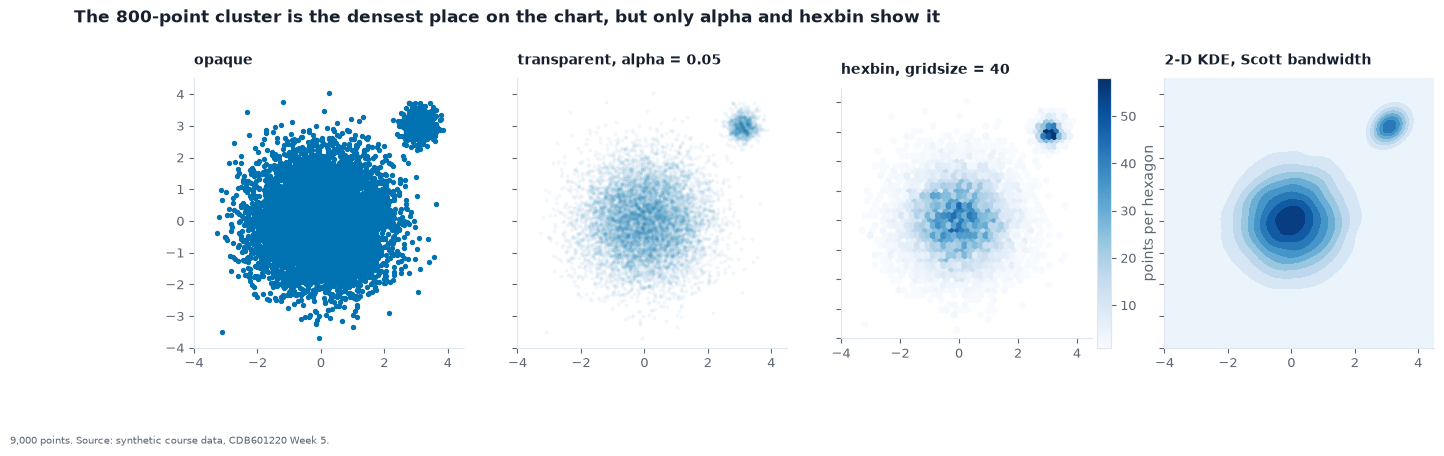

In [3]:
sd = pd.read_csv(DATA / "scatter_dense.csv")
CX, CY = 3.1, 3.0
ALPHA, GRID = 0.05, 40
near = ((sd.x - CX) ** 2 + (sd.y - CY) ** 2 < 0.5 ** 2)
centre = (sd.x ** 2 + sd.y ** 2 < 0.5 ** 2)
print(f"points within 0.5 of the cluster centre: {near.sum()}; within 0.5 of the main centre (0,0): {centre.sum()}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharex=True, sharey=True)
axes[0].scatter(sd.x, sd.y, s=8, color=BLUE)
axes[0].set_title("opaque", fontsize=10)
axes[1].scatter(sd.x, sd.y, s=8, color=BLUE, alpha=ALPHA, lw=0)
axes[1].set_title(f"transparent, alpha = {ALPHA}", fontsize=10)
hb = axes[2].hexbin(sd.x, sd.y, gridsize=GRID, cmap=PALETTE["sequential"], mincnt=1)
fig.colorbar(hb, ax=axes[2], fraction=0.05, pad=0.02).set_label("points per hexagon")
axes[2].set_title(f"hexbin, gridsize = {GRID}", fontsize=10)
kde = gaussian_kde(sd[["x", "y"]].T.values)
X, Y = np.mgrid[-4:4.5:200j, -4:4.5:200j]
Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)
axes[3].contourf(X, Y, Z, levels=12, cmap=PALETTE["sequential"])
axes[3].set_title("2-D KDE, Scott bandwidth", fontsize=10)
for ax in axes:
    ax.set_aspect("equal")
    ax.grid(False)
peak = np.unravel_index(Z.argmax(), Z.shape)
print(f"KDE peak at ({X[peak]:.1f}, {Y[peak]:.1f}); KDE height at the cluster / at the peak: "
      f"{kde([[CX], [CY]])[0] / Z.max():.2f}")
hx = hb.get_array()
xy = hb.get_offsets()
top = xy[np.argmax(hx)]
print(f"densest hexagon: {hx.max():.0f} points at ({top[0]:.1f}, {top[1]:.1f})")
fig.suptitle("The 800-point cluster is the densest place on the chart, but only alpha and hexbin show it",
             x=0.05, ha="left", fontweight="bold")
save_fig(fig, CHARTS / "b2_overplotting.png", note="9,000 points. Source: synthetic course data, CDB601220 Week 5.")

| View | Is the cluster at (3.1, 3.0) visible? |
|---|---|
| Opaque | **As a shape, yes. As a quantity, no.** It looks like a small solid blob next to a big solid blob. Opaque ink saturates at one point per spot, so 709 points in a small circle look the same as a handful. |
| Transparent (`alpha = 0.05`) | **Yes, clearly.** It's darker than the main mass, because it's denser. |
| Hexbin (`gridsize = 40`) | **Yes, and quantified.** The densest hexagon on the whole chart is in the cluster. The colourbar gives counts. |
| 2-D KDE (Scott) | **Yes, but understated.** One global bandwidth, tuned to the wide main mass, smears the tight cluster, which then looks fainter than the centre. |

**I'd publish the hexbin.** It's the only one of the four that turns density into a number the reader can
check against a legend. The alpha version depends on screen and print gamma, and the KDE's bandwidth is a
hidden parameter that here gets the comparison backwards. Parameters declared: `alpha = 0.05`,
`gridsize = 40`, KDE bandwidth = Scott's rule.

## 3 · Scaling and dimension reduction

In [4]:
scaled = {how: g.scale_frame(hi, NUM, how)["gdp_pc"] for how in ("minmax", "zscore", "rank")}
ald = hi.gdp_pc.idxmax()
rows = []
for how, s_ in scaled.items():
    rest = s_.drop(ald)
    rows.append({"scaling": how, "Aldonia": round(s_[ald], 2), "median": round(s_.median(), 3),
                 "other 59: min": round(rest.min(), 2), "other 59: max": round(rest.max(), 2),
                 "share of axis used by the other 59": f"{(rest.max() - rest.min()) / (s_.max() - s_.min()):.0%}"})
pd.DataFrame(rows)

,scaling,Aldonia,median,other 59: min,other 59: max,share of axis used by the other 59
0,minmax,1.0,0.017,0.00,0.11,11%
1,zscore,7.5,-0.225,-0.36,0.47,11%
2,rank,1.0,0.508,0.02,0.98,98%


- **Min–max:** Aldonia takes 1.0, and the other 59 countries are squeezed into the bottom 11% of the axis
  (median 0.017).
- **z-score:** Aldonia is **7.5 standard deviations** out. The other 59 are still squeezed into 11% of the
  axis, because the outlier inflates the standard deviation they're divided by.
- **Rank:** everyone is evenly spread from 0.017 to 1, and Aldonia is just "1st". It's immune to the
  outlier, but it throws away the fact that Aldonia is 9.2× the next country.

In [5]:
Z = g.scale_frame(hi, NUM, "zscore")
pca = PCA().fit(Z)
evr = pca.explained_variance_ratio_
print("explained variance ratio:", np.round(evr, 3).tolist())
print(f"first two components: {evr[:2].sum():.1%}  ->  a two-axis picture misses {1 - evr[:2].sum():.1%}")
print(pd.DataFrame(pca.components_[:2].T, index=NUM, columns=["PC1", "PC2"]).round(2))

explained variance ratio: [0.675, 0.162, 0.077, 0.065, 0.022]
first two components: 83.7%  ->  a two-axis picture misses 16.3%
                    PC1   PC2
gdp_pc             0.32  0.87
healthcare_access  0.51 -0.25
urban_pct          0.46 -0.07
median_age         0.45 -0.40
cases_per_100k    -0.47 -0.13


PCA on the standardised columns: PC1 explains **67.5%** and PC2 **16.2%**, so **83.7%** together. A
two-axis picture of this dataset misses **16.3%** of its variance. PC1 is the "development" axis (access, urban,
age up, cases down), and PC2 is mostly GDP, which is partly Aldonia pulling a component towards itself.

## 4 · Project before you measure

In [6]:
feats = g.read_geojson(DATA / "districts.geojson")
codes = [f["code"] for f in feats]


def shoelace_deg(ring):
    x = np.array([p[0] for p in ring])
    y = np.array([p[1] for p in ring])
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


sph = pd.Series([g.polygon_area_km2(f["ring"]) for f in feats], index=codes)
deg = pd.Series([shoelace_deg(f["ring"]) for f in feats], index=codes)
lat = pd.Series([g.representative_point(f["ring"])[1] for f in feats], index=codes)
north = lat.nlargest(4).index
share_sph, share_deg = sph / sph.sum(), deg / deg.sum()
worst = (share_deg / share_sph - 1).abs().idxmax()
print(f"four northernmost: {list(north)}")
print(f"their share of the land: spherical {share_sph[north].sum():.2%}, shoelace on degrees {share_deg[north].sum():.2%}")
print(f"most distorted district: {worst}, {share_sph[worst]:.2%} -> {share_deg[worst]:.2%} "
      f"({share_deg[worst] / share_sph[worst] - 1:+.1%})")
merc = 1 / np.cos(np.radians(lat)) ** 2
print(f"Mercator area inflation (sec^2 lat): {merc.min():.2f}x in the south to {merc.max():.2f}x in the north "
      f"-> north drawn {merc.max() / merc.min():.2f}x bigger relative to the south")

four northernmost: ['D21', 'D22', 'D19', 'D24']
their share of the land: spherical 10.51%, shoelace on degrees 11.08%
most distorted district: D21, 2.15% -> 2.27% (+5.6%)
Mercator area inflation (sec^2 lat): 1.24x in the south to 1.49x in the north -> north drawn 1.21x bigger relative to the south


- The four northernmost districts (D21, D22, D19, D24) are **10.51%** of the land on the sphere and
  **11.08%** when measured in raw degrees. The most distorted single district is **D21**, which gains
  **5.6%**. A square degree shrinks towards the pole, so degree-space over-weights the north.
- **Mercator** inflates area by sec²(latitude): **1.24×** at the southern edge and **1.49×** at the northern
  edge, so a northern district is drawn **1.21× larger** than a southern district of the same real size.
  (`geolib`'s own self-check prints sec(lat), the *linear* scale factor, 1.14–1.17×. Area goes as its
  square.)

A choropleth encodes the value as colour *spread over an area*. If the projection inflates northern areas
by 21%, northern values get 21% more ink for the same land, and the projection itself has edited the data.
That's why a choropleth needs an equal-area projection (slide 34).

## 5 · Small-area stability

pooled 8.72 per 100k; outside the 95% limits: 1 of 40 -> ['U32']
18 outside the funnel around 9 from population 42,700
the two 95% bands stop overlapping from population 248,800


'charts\\b5_funnel.png'

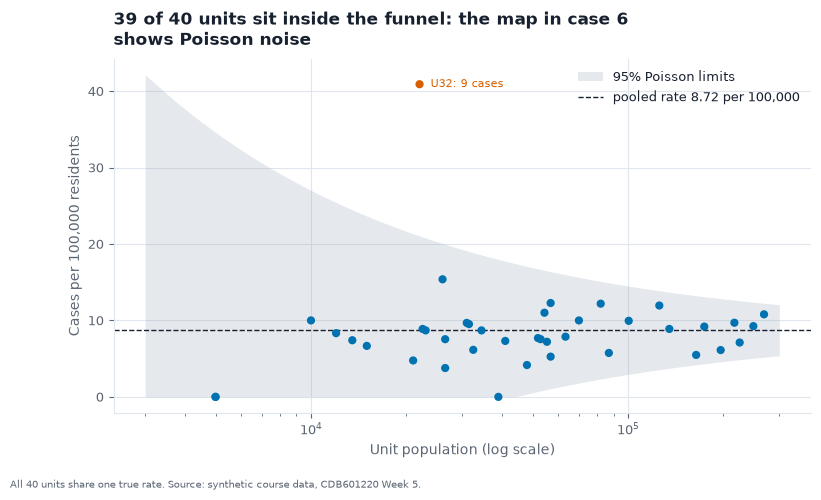

In [7]:
sa = pd.read_csv(DATA / "smallarea_cases.csv")
sa["rate"] = sa.cases / sa.population * 1e5
pooled = sa.cases.sum() / sa.population.sum() * 1e5
sa["lo"] = pooled - 1.96 * np.sqrt(pooled / 1e5 * sa.population) / sa.population * 1e5
sa["hi"] = pooled + 1.96 * np.sqrt(pooled / 1e5 * sa.population) / sa.population * 1e5
outside = sa[(sa.rate < sa.lo) | (sa.rate > sa.hi)]
print(f"pooled {pooled:.2f} per 100k; outside the 95% limits: {len(outside)} of 40 -> {outside.unit.tolist()}")

# 9 vs 18 per 100k: the smallest population at which 18 falls outside 9's 95% funnel,
# and the stricter one at which the two 95% bands stop overlapping
p = np.arange(1_000, 400_001, 100)
upper9 = 9 + 1.96 * np.sqrt(9e-5 * p) / p * 1e5
lower18 = 18 - 1.96 * np.sqrt(18e-5 * p) / p * 1e5
print(f"18 outside the funnel around 9 from population {p[upper9 < 18][0]:,}")
print(f"the two 95% bands stop overlapping from population {p[upper9 < lower18][0]:,}")

fl = g.funnel_limits(np.linspace(3_000, 300_000, 400), pooled)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.fill_between(fl.population, fl.lo, fl.hi, color=GREY, alpha=0.25, lw=0, label="95% Poisson limits")
ax.axhline(pooled, color=INK, ls="--", lw=1, label=f"pooled rate {pooled:.2f} per 100,000")
ax.scatter(sa.population, sa.rate, color=[ORANGE if u in set(outside.unit) else BLUE for u in sa.unit], s=24, zorder=3)
for r in outside.itertuples():
    ax.annotate(f"{r.unit}: {r.cases} cases", (r.population, r.rate), xytext=(8, 0), textcoords="offset points",
                fontsize=8, color=ORANGE, va="center")
ax.set_xscale("log")
ax.set_xlabel("Unit population (log scale)")
ax.set_ylabel("Cases per 100,000 residents")
ax.legend(loc="upper right")
ax.set_title(textwrap.fill("39 of 40 units sit inside the funnel: the map in case 6 shows Poisson noise", 60))
save_fig(fig, CHARTS / "b5_funnel.png", note="All 40 units share one true rate. Source: synthetic course data, CDB601220 Week 5.")

- **1 of 40 units (U32) falls outside** the 95% limits. With 40 units, about 2 would land outside by chance
  alone, so one outlier is *fewer* than noise predicts. The case 6 map is a map of sampling noise, and its
  darkest unit is the one with the smallest denominator, not the highest risk.
- **Telling 9 from 18 per 100,000.** A rate of 18 falls outside the 95% funnel around 9 from a population
  of about **42,700**. For the two rates' 95% ranges to stop overlapping entirely, you need about **248,800**
  people. Below roughly 43,000, a district at twice the national rate can't be told apart from one at the
  national rate. That's a suppression threshold, not a detail.